# HW4 - Design of Experiments

Amanda Yaklin

yaklin2@illinois.edu

Design of experiments for circuit board machining data

All 4 combinations of 2 speeds (40 RPM and 90 RPM) and 2 mill diameters 
(1/16 in and 1/8 in) are used to machine notches in a circuit board. 
Degree of board vibration is measured for each test, and the experiments 
are repeated 4 times. 

The objective of this project is to measure the effect of 
mill diameter and rotation speed on the vibration level and determine 
an optimal combination of inputs for this manufacturing process to minimize 
vibration.

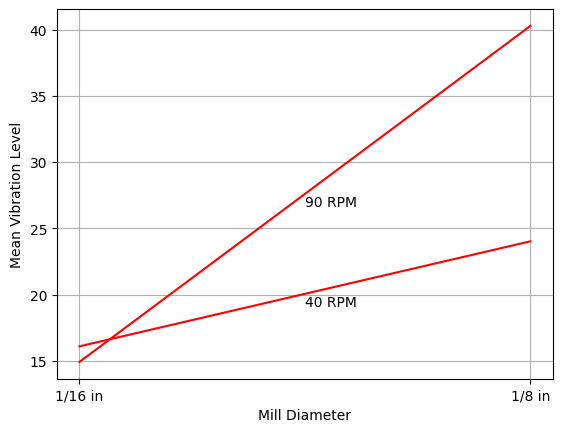

In [ ]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

filename = 'circuit-board.csv'

def dataset(filename):
    resp = pd.read_csv(filename).to_numpy() # response data
    n_reps = resp.shape[0] # no. of replicates
    return resp, n_reps
    
def effects(responses, n_replicates):
    """Function to calculate main and interaction effects for a 2^2 factorial experiment.

    Parameters
    ----------
    responses : array_like
        Input response data (4 x n_replications dimensions), where each row is an observed response for a condition (ordered in the standard order) and each column is a replicate.
        For example, responses[0,1] = response from replicate 1 for condition (1), responses[1,1] = response from replicate 1 for condition a.
    n_replicates : int
        Number of replications in the experiment data.

    Returns
    -------
    effects : array_like
        Calculated effects (3 x 1 dimensions) for a, b, and ab.

    Notes
    -----
    Standard order of experiment conditions (order of rows in responses) = (1), a, b, ab
    (1) = both low
    a = only a high
    b = only b high
    ab = both high
    """

    # effect of a
    A = ((np.mean(responses[1])-np.mean(responses[0])) + (np.mean(responses[3])-np.mean(responses[2])))/2
    
    # effect of b
    B = ((np.mean(responses[2])-np.mean(responses[0])) + (np.mean(responses[3])-np.mean(responses[1])))/2
    
    # effect of a on b
    AB = ((np.mean(responses[3])-np.mean(responses[2])) - (np.mean(responses[1])-np.mean(responses[0])))/2
    
    return np.array([A, B, AB])

def plot_effects(responses, n_replicates):
    """Function to plot effects for a 2^2 factorial experiment.

    Parameters
    ----------
    responses : array_like
        Input response data (4 x n_replications dimensions), where each row is an observed response for a condition (ordered in the standard order) and each column is a replicate.
        For example, responses[0,1] = response from replicate 1 for condition (1), responses[1,1] = response from replicate 1 for condition a.
    n_replicates : int
        Number of replications in the experiment data.

    Returns
    -------
    out : list
        List of artists added.

    Notes
    -----
    This function structure is based on matplotlib's suggested signature function for returning a plot:
    https://matplotlib.org/3.5.0/tutorials/introductory/usage.html#the-object-oriented-interface-and-the-pyplot-interface
    """
    # plot R vs A +, - for B +, -
    
    label_y_pos = -0.9 # position B=high, B=low w.r.t line in the y-direction
    
    fig, ax = plt.subplots()
    B_minus = [np.mean(responses[0]), np.mean(responses[1])]
    B_plus = [np.mean(responses[2]), np.mean(responses[3])]
    A = [0,1]
    
    out1 = ax.plot(A, B_plus, color='red')
    out2 = ax.plot(A, B_minus, color='red')
    ax.text(np.median(A),np.median(B_plus)+label_y_pos, '90 RPM')
    ax.text(np.median(A),np.median(B_minus)+label_y_pos, '40 RPM')
    ax.set_xlabel('Mill Diameter')
    ax.set_ylabel('Mean Vibration Level')
    ax.grid()
    ax.set_xticks(A)
    ax.set_xticklabels(['1/16 in','1/8 in'])
    return out1, out2


responses, n_replicates = dataset(filename)
eff = effects(responses,n_replicates)
out1, out2 = plot_effects(responses, n_replicates)

The line plot shows the degree of interaction effect. Parallel lines 
indicate no interaction, as equal changes in vibration would be observed
due to modification of mill diameter regardless of RPM. The skewed lines 
show that varying the RPM influences the sensitivity of the system to changes 
in mill diameter. At 90 RPM, a greater increase in vibration is observed 
with increased mill diameter than at 40 RPM.

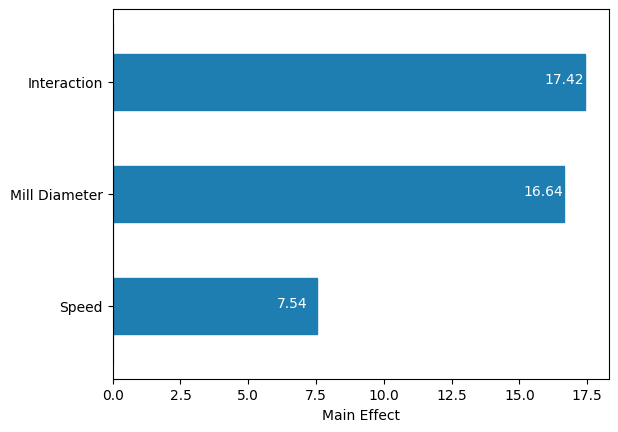

In [12]:
def plot_tornado(responses, n_replicates):
    """Function to make a tornado plot for a 2^2 factorial experiment.

    Parameters
    ----------
    responses : array_like
        Input response data (4 x n_replications dimensions), where each row is an observed response for a condition (ordered in the standard order) and each column is a replicate.
        For example, responses[0,1] = response from replicate 1 for condition (1), responses[1,1] = response from replicate 1 for condition a.
    n_replicates : int
        Number of replications in the experiment data.

    Returns
    -------
    out : list
        List of artists added.

    Notes
    -----
    This function structure is based on matplotlib's suggested signature function for returning a plot:
    https://matplotlib.org/3.5.0/tutorials/introductory/usage.html#the-object-oriented-interface-and-the-pyplot-interface
    """
    colors=["#AF1042","#1F7EB1"]
    labels = np.char.array(['Mill Diameter','Speed','Interaction'])
    eff = effects(responses, n_replicates)
    baseline = 0.0
    eff = np.array(eff)
    bars = eff - baseline
    fig, ax = plt.subplots()
    sort_i = np.argsort(bars)
    bars = bars[sort_i]
    labels = labels[sort_i]
    out = ax.barh(labels, bars, height=0.5,)
    ax.set_xlabel('Main Effect')
    plt.plot([0,0],[-0.5,2.5], color='black')
    i = 0
    for bar in out:
        if bars[i] <0:
            plt.text(bars[i]+0.1,i-0.1,f'{np.round(bars[i],2)}',color='white')
            bar.set_color(colors[0])
        else:
            plt.text(bars[i]-1.5,i-0.01,f'{np.round(bars[i],2)}',color='white')
            bar.set_color(colors[1])
        i+=1
    return out
out = plot_tornado(responses, n_replicates)

Of the three parameters used, vibration level is most sensitive to mill 
diameter and least sensitive to the angular speed of the mill. 
When mill size and speed are changed, the effect is slightly greater 
than that of rotation speed alone. 
This interaction effect is established by the line plot as well.

In [30]:
from scipy.stats import f
from scipy.stats import ttest_ind

def anova(filepath,predictors):
    print('analysis of variance')
    y, n_replicates = dataset(filepath) # rows = replicates; cols = experiments
    y = y.T
    y_bar_i = np.mean(y, axis=0) # array of means of rows
    y_bar = np.mean(y) # mean of all data
    k = y_bar_i.shape[0] # no. of experiments
    n = len(y.flatten()) # total no. of samples across all groups
    print("group means (1, A, B, AB):",np.round(y_bar_i,2))
    print("overall mean:",y_bar)
    df1 = k-1 # degrees of freedom of between-group variance
    df2 = n-k # degrees of freedom of within-group variance
    explained_variance = np.sum((y_bar_i - y_bar)**2/df1)
    group_variance = np.sum((y-y_bar_i)**2/df2, axis = 0)
    unexplained_variance = np.sum(group_variance)
    print('group variances (1, A, B, AB):', np.round(group_variance,2))
    print('group standard deviations (1, A, B, AB):', np.round(np.sqrt(group_variance),2))
    F = explained_variance/unexplained_variance
    print('f:', F)
    p = f.sf(F,df1,df2) # use scipy to compute p-stat
    print('p:',p)
    # Welch's t-test
    for i in range(len(y_bar_i)):
        for j in range(i+1, len(y_bar_i)):
            if i != j:
                t, p_val = ttest_ind(y.T[i],y.T[j],equal_var=False)
                print(f'{predictors[i]} vs {predictors[j]} t-value: {np.round(t,2)}, p-value:{np.round(p_val, 6)}')
    return group_variance, y_bar_i
vari, avg = anova(filename,['1','A','B','AB'])

analysis of variance
group means (1, A, B, AB): [16.1  24.02 14.92 40.28]
overall mean: 23.83125
group variances (1, A, B, AB): [2.11 1.25 0.14 2.47]
group standard deviations (1, A, B, AB): [1.45 1.12 0.38 1.57]
f: 22.83958137265154
p: 3.000952763009751e-05
1 vs A t-value: -4.32, p-value:0.005781
1 vs B t-value: 0.78, p-value:0.484912
1 vs AB t-value: -11.29, p-value:3e-05
A vs B t-value: 7.71, p-value:0.002163
A vs AB t-value: -8.42, p-value:0.000258
B vs AB t-value: -15.7, p-value:0.000302


The standard ANOVA F-test assumes equal variance for each 
group. Since the group variances for the machining dataset 
are not equal, a Welch's t-test is used instead. The results of Welch's t-test show that individual changes in experimental conditions produce significant changes in the average response, except the change in RPM with the 1/16 inch diameter mill (p=0.48), with group variation taken into account. 

To minimize vibration levels, the best combinations are the 1/16 in mill at 40 RPM and the 1/16 in mill at 90 RPM with 90 RPM producing the lowest average vibration level. Using the given RPM values, the 1/8 in mill always produces higher vibration levels. Further testing is needed to determine if a lower or higher RPM would be compatible with the 1/8 in mill.